In [1]:
import os
import torch
import scanpy as sc
import numpy as np
from preprocess import normalize, get_top_down_cluster_ids
from Tumor_plts import plt_show_adata, plot_umap_embeddings, CCA_corr_analyse, plot_top_genes
from Tumor_evaluation_metrics import evaluate_scib
torch.manual_seed(0)

In [2]:
name = '3515_Lkb1_T1_Fam'
pruned_adata = sc.read_h5ad(f'./data/preprocessed/{name}_pruned_adata.h5ad')
pruned_adata

AnnData object with n_obs × n_vars = 1878 × 4000
    obs: 'TS_Present', 'RNA_Present', 'MULTI', 'TS_UMI', 'NUM_INTBC', 'Lane', 'Tumor', 'SubTumor', 'ES_clone', 'genotype', 'Aging_time', 'Mouse', 'Aging_Month', 'Batch_Library', 'Batch_Harvest', 'Aging_Time', 'MetFamily', 'lentiBC', 'LentiFiltered', 'is_normal', 'PercentUncut', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'Cluster', 'Cluster-Name'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'Batch_Library_colors', 'C_scANVI_colors', 'Cluster-Name_colors', 'Cluster_colors', 'Combined_Clusters_colors', 'Mouse_colors', 'NT_leiden_colors', '_scvi', 'genotype_colors', 'hvg', 'leiden', 'leiden_0.2_colors', 'leiden_0.4_colors', 'leiden_0.6_colors', 'leiden_0.8_colors', 'leiden_1.0_colors', 'leiden_1.5_colors', 'neighbors', 'umap'


In [3]:
keep = np.array((pruned_adata.X > 0).sum(axis=0) >= 10).flatten()
print('genes expressed in 10 or more cells:', np.sum(keep))
pruned_adata = pruned_adata[:, keep].copy()
if hasattr(pruned_adata.X, "toarray"):
    dense_array = pruned_adata.X.toarray()
else:
    dense_array = np.asarray(pruned_adata.X)
pruned_adata.X = dense_array


genes expressed in 10 or more cells: 717


In [4]:
sc.pp.highly_variable_genes(pruned_adata, flavor="seurat_v3", n_top_genes=200, subset=True)
pruned_adata = normalize(pruned_adata,
                  size_factors=True,
                  normalize_input=True,
                  logtrans_input=True)

print(pruned_adata)

AnnData object with n_obs × n_vars = 1878 × 200
    obs: 'TS_Present', 'RNA_Present', 'MULTI', 'TS_UMI', 'NUM_INTBC', 'Lane', 'Tumor', 'SubTumor', 'ES_clone', 'genotype', 'Aging_time', 'Mouse', 'Aging_Month', 'Batch_Library', 'Batch_Harvest', 'Aging_Time', 'MetFamily', 'lentiBC', 'LentiFiltered', 'is_normal', 'PercentUncut', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'Cluster', 'Cluster-Name', 'n_counts', 'size_factors'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'Batch_Library_colors', 'C_scANVI_colors', 'Cluster-Name_colors', 'Cluster_colors', 'Combined_Clusters_colors', 'Mouse_colors', 'NT_leiden_colors', '_scvi', 'genotype_colors', 'hvg', 'leiden', 'leiden_0.2_colors', 'leiden_0.4_colors', 'leiden_0.6_colors', 'leiden_0.8_colors', 'leiden_1.0_colors',

In [5]:
tree_path = f'./data/preprocessed/{name}_pruned.nwk'
with open(f'./data/preprocessed/{name}_cells.txt') as f:
    labels_in_order = np.array(f.read().splitlines())
_, top_down_clusters = get_top_down_cluster_ids(tree_path, labels_in_order, depth=4)
pruned_adata.obs['subtree'] = top_down_clusters
adata = pruned_adata

In [6]:
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcdefaults()

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'savefig.facecolor': 'white',
    'savefig.edgecolor': 'none',
    'savefig.transparent': False,

    'text.color':       'black',
    'axes.labelcolor':  'black',
    'axes.edgecolor':   'black',
    'xtick.color':      'black',
    'ytick.color':      'black',

    'legend.facecolor': 'white',
    'legend.edgecolor': 'black',
    'legend.frameon':   False,
})

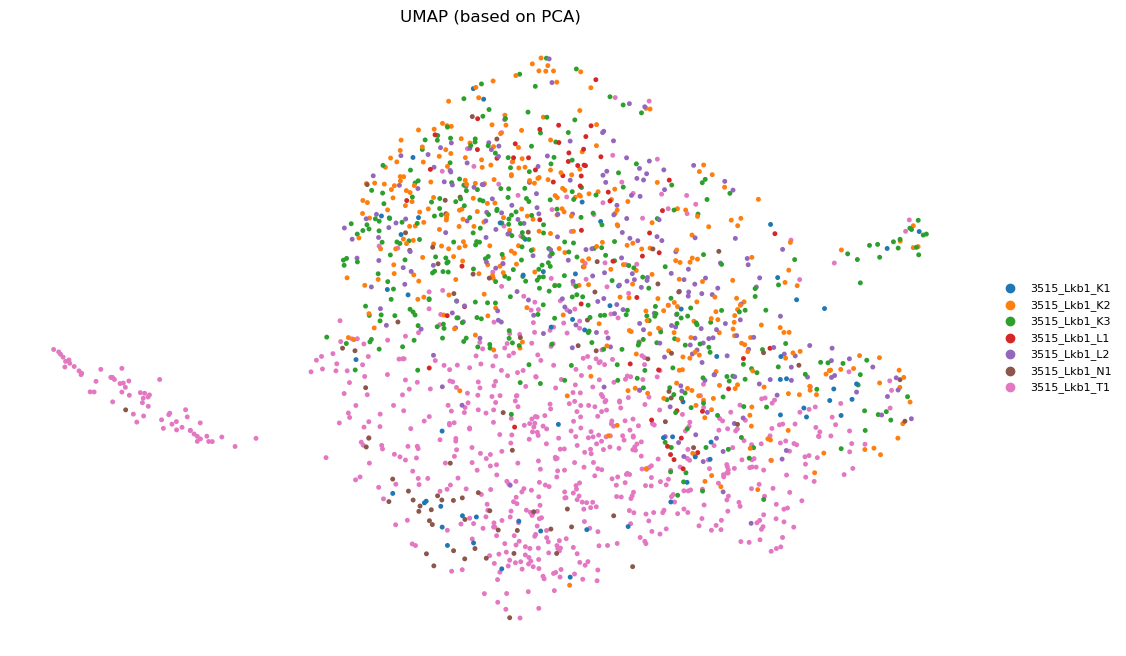

In [7]:
adata.obs['Tumor'] = adata.obs['Tumor'].astype('category')
results_path = '.results_3515/Figures'
os.makedirs(results_path, exist_ok=True)
plt_show_adata(adata, 'Tumor', 50, name, results_path)

In [8]:
final_latent = np.loadtxt('3515_final_latent.txt', delimiter=",")
gp_latent = np.loadtxt('3515_gp_latent.txt', delimiter=",")
gaussian_latent = np.loadtxt('3515_gaussian_latent.txt', delimiter=",")

PORCELAN_results_path = "./Tumor_PORCELAN/results_all"
PORCELAN_latent = np.load(f'{PORCELAN_results_path}/{name}_latent_genes_PORCELAN_1000.npy')

adata.obsm["DeepTracing_UV"] = final_latent
adata.obsm["DeepTracing_LV"] = gp_latent
adata.obsm["DeepTracing_IV"] = gaussian_latent
adata.obsm["PORCELAN"] = PORCELAN_latent

adata.obsm["PCA"] = adata.obsm["X_pca"]
adata.obsm["scVI"] = adata.obsm["X_scVI"]


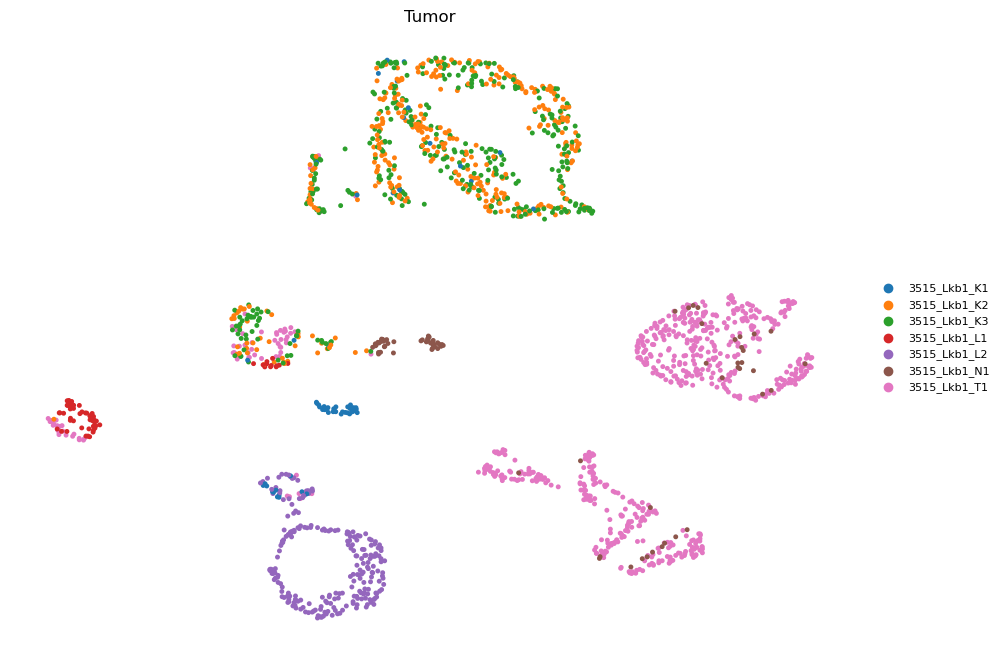

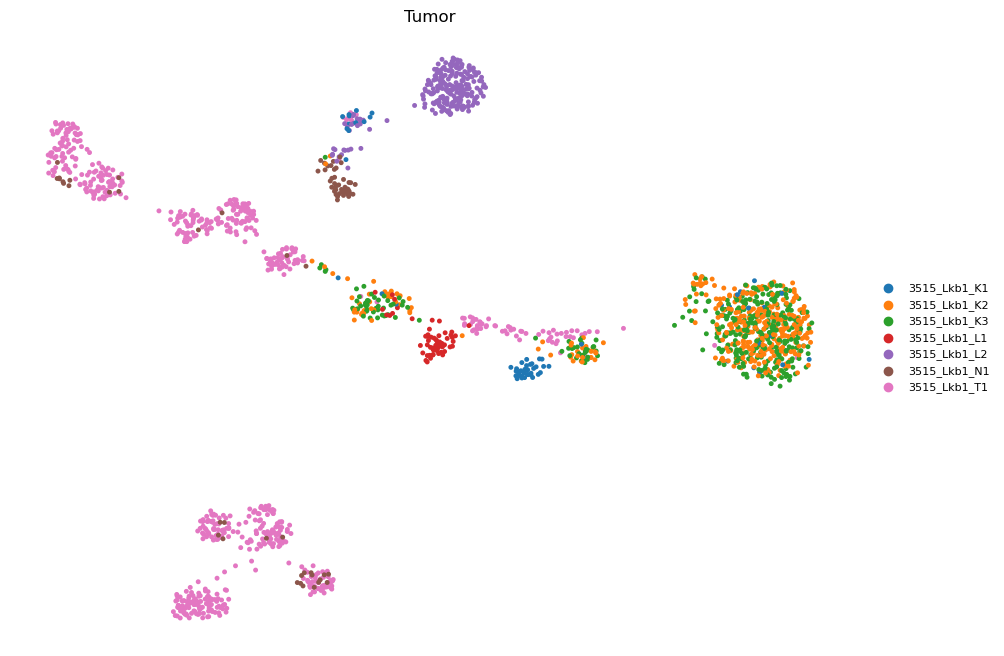

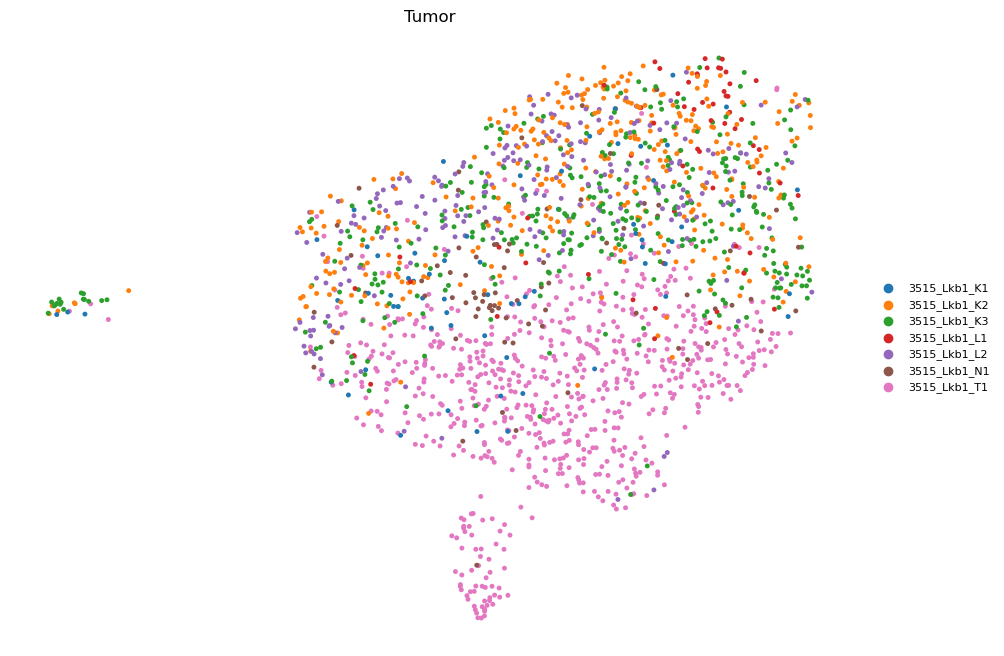

In [9]:
color_keys = ["Tumor"]
plot_umap_embeddings(adata, rep_keys=["DeepTracing_UV", "PORCELAN", "scVI"],
                     color_keys=color_keys, size=50, name=name, results_path=results_path)

        cca_corr
Clu     0.154077
Sftpc   0.060167
Cldn18  0.039157
Hp      0.021002
Gnat3   0.018327


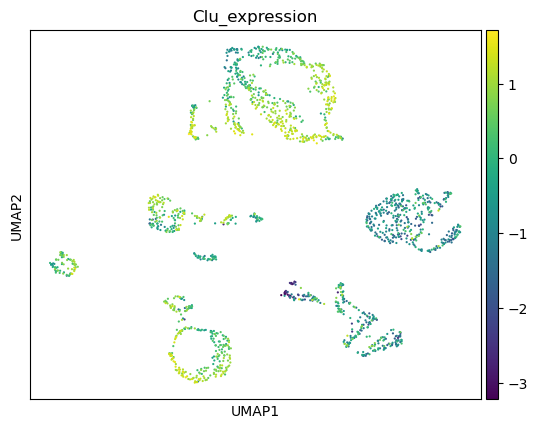

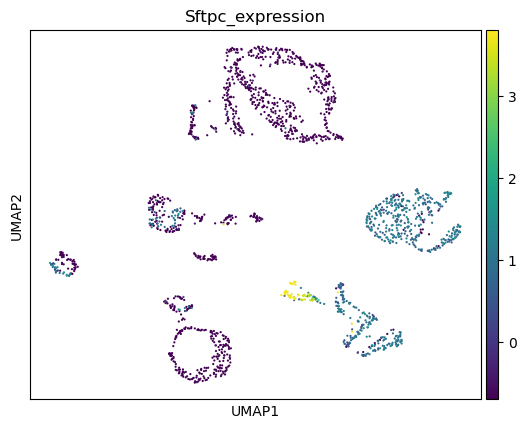

In [10]:
X_cca_corr_df_sorted = CCA_corr_analyse(adata, final_latent)
print(X_cca_corr_df_sorted.head())
plot_top_genes(adata, "DeepTracing_UV", X_cca_corr_df_sorted, 2)

Evaluating Tumor Type Conservation...


Metrics:   0%|          | 0/5 [00:00<?, ?it/s, Bio conservation: nmi_ari_cluster_labels_kmeans]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 6/6 [00:12<00:00,  2.09s/it]o conservation: silhouette_label]

           

Evaluating Lineage Conservation...


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 6/6 [00:43<00:00,  7.31s/it]o conservation: silhouette_label]

                                                                                          

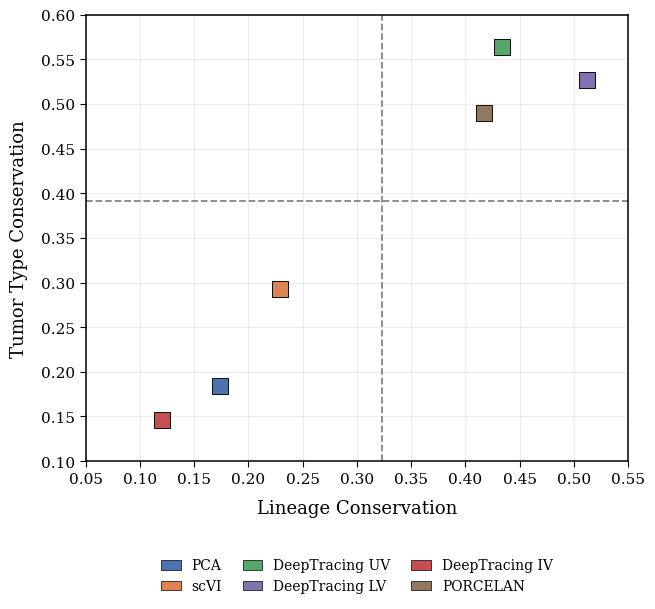

In [11]:
embedding_keys = ["PCA", "scVI", "DeepTracing_UV", "DeepTracing_LV", "DeepTracing_IV", "PORCELAN"]
label_configs = [("Tumor Type", "Tumor"), ("Lineage", "subtree")]

full_metrics, summary_scores, benchmarkers, scatter_files = evaluate_scib(
    adata=adata,
    embedding_keys=embedding_keys,
    label_configs=label_configs,
    output_dir=f"./evaluation_metrics_results_{name}",
    n_jobs=8,
    show=True,
    scatter_pairs=[("Lineage Conservation", "Tumor Type Conservation")],
)


In [12]:
name = '3724_NT_All'
pruned_adata = sc.read_h5ad(f'./data/preprocessed/{name}_filtered_pruned_adata.h5ad')
print(pruned_adata)

AnnData object with n_obs × n_vars = 20865 × 4000
    obs: 'TS_Present', 'RNA_Present', 'MULTI', 'TS_UMI', 'NUM_INTBC', 'Lane', 'Tumor', 'SubTumor', 'ES_clone', 'genotype', 'Aging_time', 'Mouse', 'Aging_Month', 'Batch_Library', 'Batch_Harvest', 'Aging_Time', 'MetFamily', 'lentiBC', 'LentiFiltered', 'is_normal', 'PercentUncut', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'Cluster', 'Cluster-Name', 'subtree'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'Batch_Library_colors', 'C_scANVI_colors', 'Cluster-Name_colors', 'Cluster_colors', 'Combined_Clusters_colors', 'Mouse_colors', 'NT_leiden_colors', '_scvi', 'genotype_colors', 'hvg', 'leiden', 'leiden_0.2_colors', 'leiden_0.4_colors', 'leiden_0.6_colors', 'leiden_0.8_colors', 'leiden_1.0_colors', 'leiden_1.5_colors', 'neighbo

In [13]:
keep = np.array((pruned_adata.X > 0).sum(axis=0) >= 10).flatten()
print('genes expressed in 10 or more cells:', np.sum(keep))
pruned_adata = pruned_adata[:, keep].copy()
if hasattr(pruned_adata.X, "toarray"):
    dense_array = pruned_adata.X.toarray()
else:
    dense_array = np.asarray(pruned_adata.X)
pruned_adata.X = dense_array

genes expressed in 10 or more cells: 1016


In [14]:
sc.pp.highly_variable_genes(pruned_adata, flavor="seurat_v3", n_top_genes=200, subset=True)

pruned_adata = normalize(pruned_adata,
                  size_factors=True,
                  normalize_input=True,
                  logtrans_input=True)
print(pruned_adata)

AnnData object with n_obs × n_vars = 20865 × 200
    obs: 'TS_Present', 'RNA_Present', 'MULTI', 'TS_UMI', 'NUM_INTBC', 'Lane', 'Tumor', 'SubTumor', 'ES_clone', 'genotype', 'Aging_time', 'Mouse', 'Aging_Month', 'Batch_Library', 'Batch_Harvest', 'Aging_Time', 'MetFamily', 'lentiBC', 'LentiFiltered', 'is_normal', 'PercentUncut', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'Cluster', 'Cluster-Name', 'subtree', 'n_counts', 'size_factors'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'Batch_Library_colors', 'C_scANVI_colors', 'Cluster-Name_colors', 'Cluster_colors', 'Combined_Clusters_colors', 'Mouse_colors', 'NT_leiden_colors', '_scvi', 'genotype_colors', 'hvg', 'leiden', 'leiden_0.2_colors', 'leiden_0.4_colors', 'leiden_0.6_colors', 'leiden_0.8_colors', 'leiden_

In [15]:
tree_path = f'./data/preprocessed/{name}_filtered_pruned.nwk'
with open(f'./data/preprocessed/{name}_filtered_cells.txt') as f:
    labels_in_order = np.array(f.read().splitlines())
_, top_down_clusters = get_top_down_cluster_ids(tree_path, labels_in_order, depth=4)
pruned_adata.obs['subtree'] = top_down_clusters
adata = pruned_adata

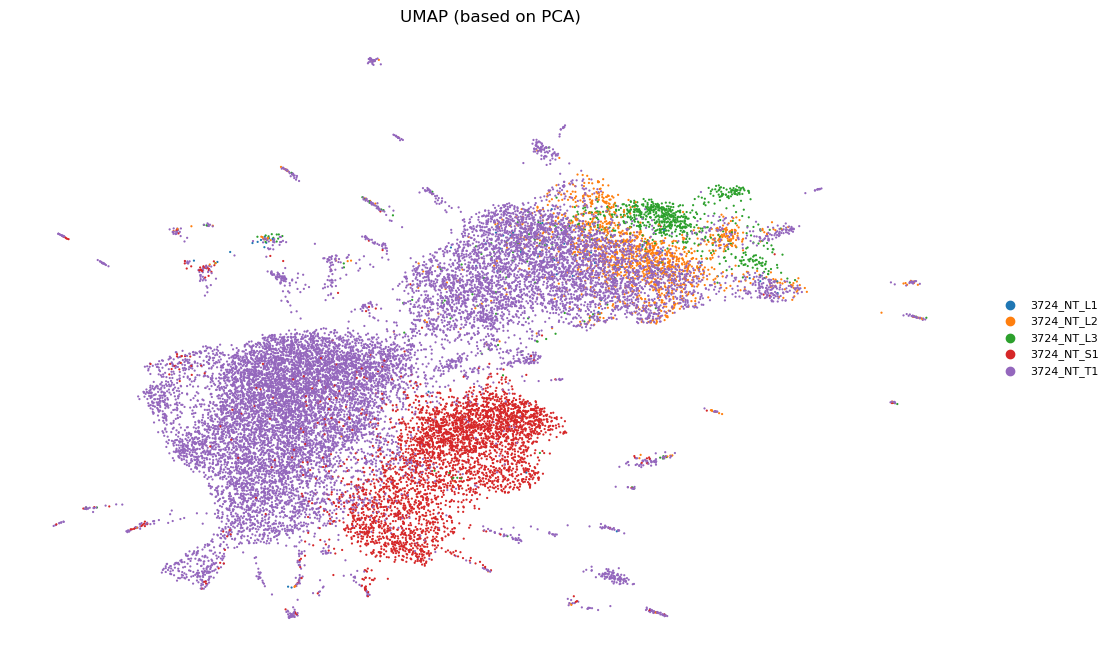

In [16]:
adata.obs['Tumor'] = adata.obs['Tumor'].astype('category')
results_path = '.results_3724/Figures'
os.makedirs(results_path, exist_ok=True)
plt_show_adata(adata, 'Tumor', 10, name, results_path)

In [18]:
final_latent = np.loadtxt('3724_filtered_final_latent.txt', delimiter=",")
gp_latent = np.loadtxt('3724_filtered_gp_latent.txt', delimiter=",")
gaussian_latent = np.loadtxt('3724_filtered_gaussian_latent.txt', delimiter=",")

adata.obsm["DeepTracing_UV"] = final_latent
adata.obsm["DeepTracing_LV"] = gp_latent
adata.obsm["DeepTracing_IV"] = gaussian_latent

adata.obsm["PCA"] = adata.obsm["X_pca"]
adata.obsm["scVI"] = adata.obsm["X_scVI"]

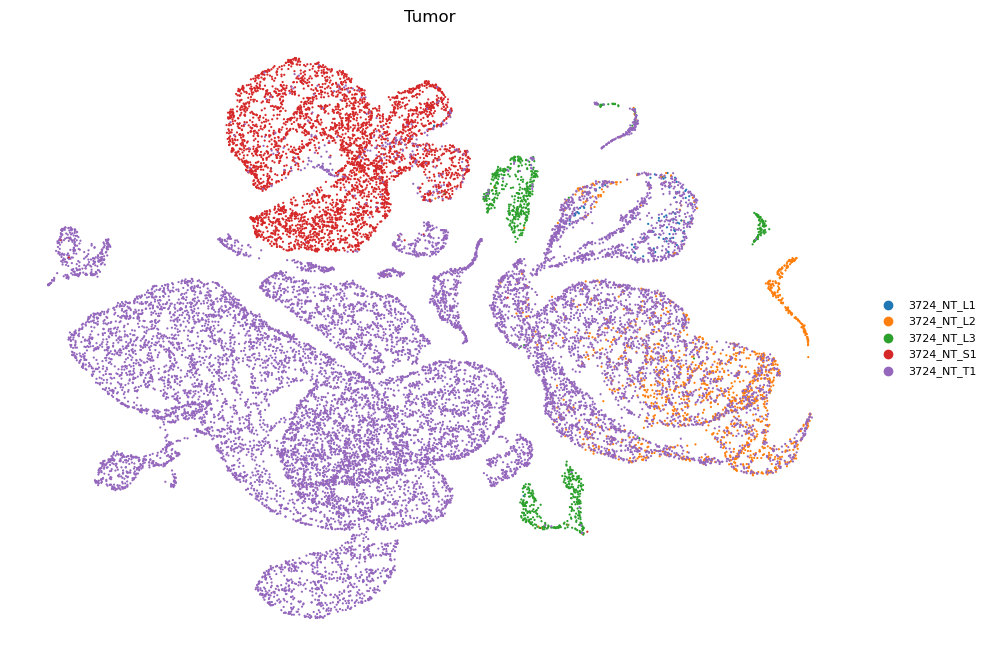

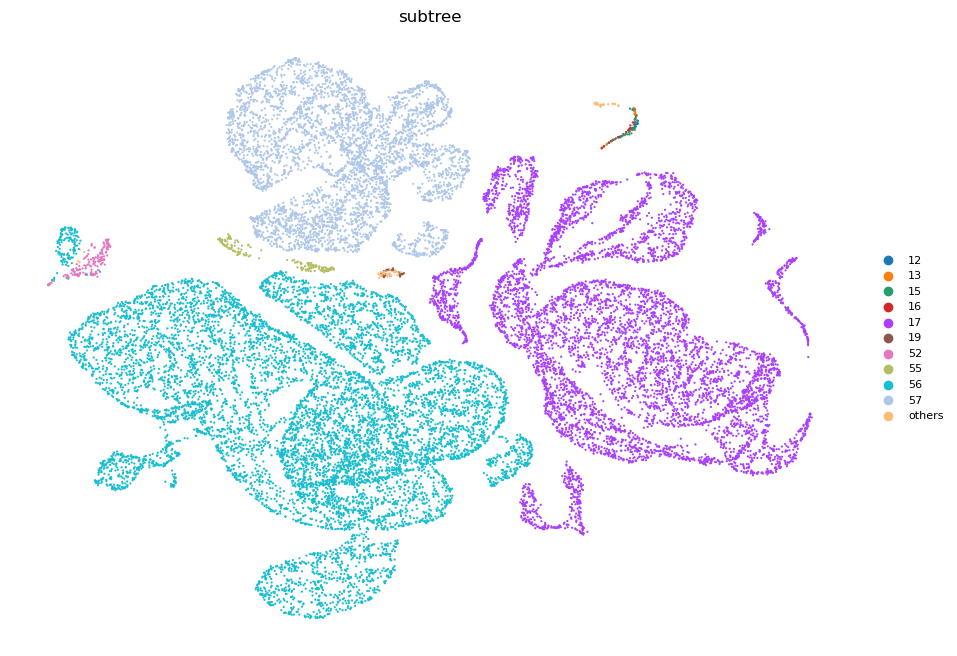

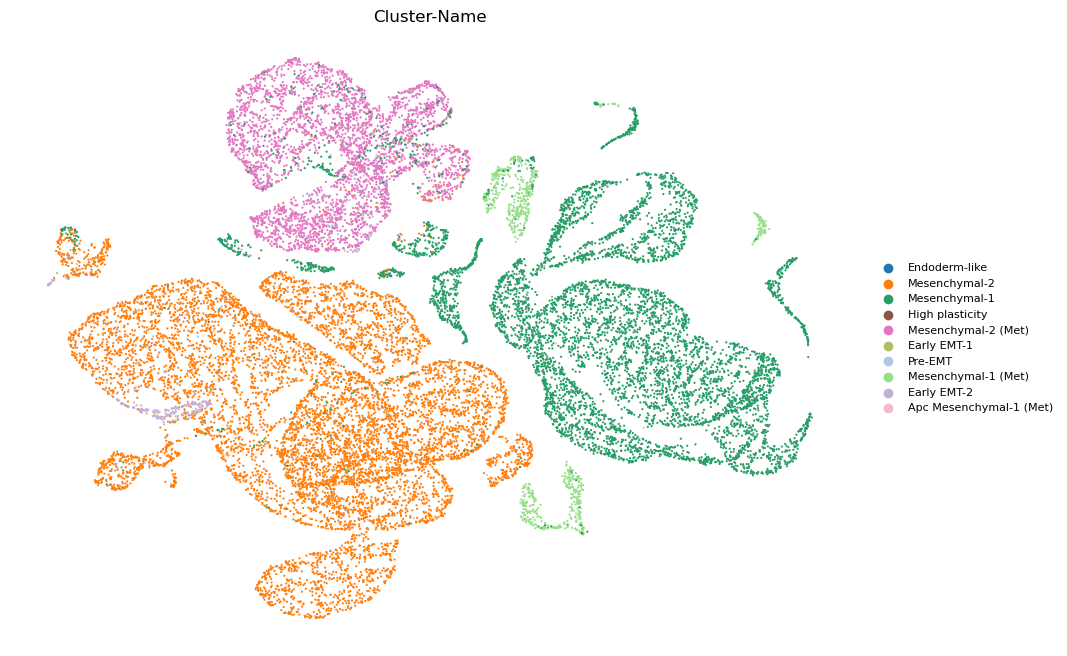

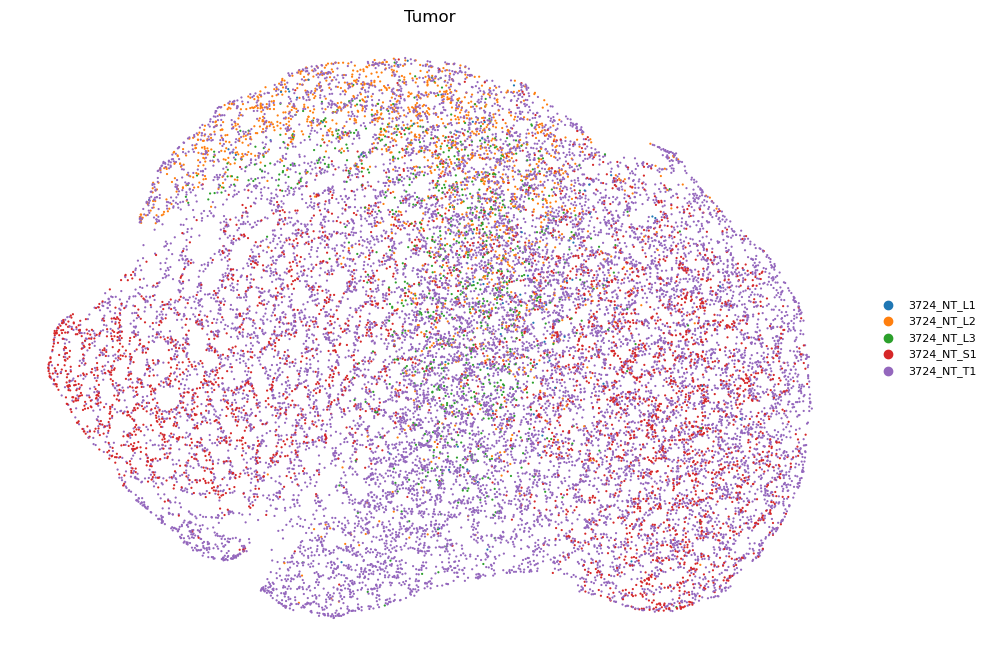

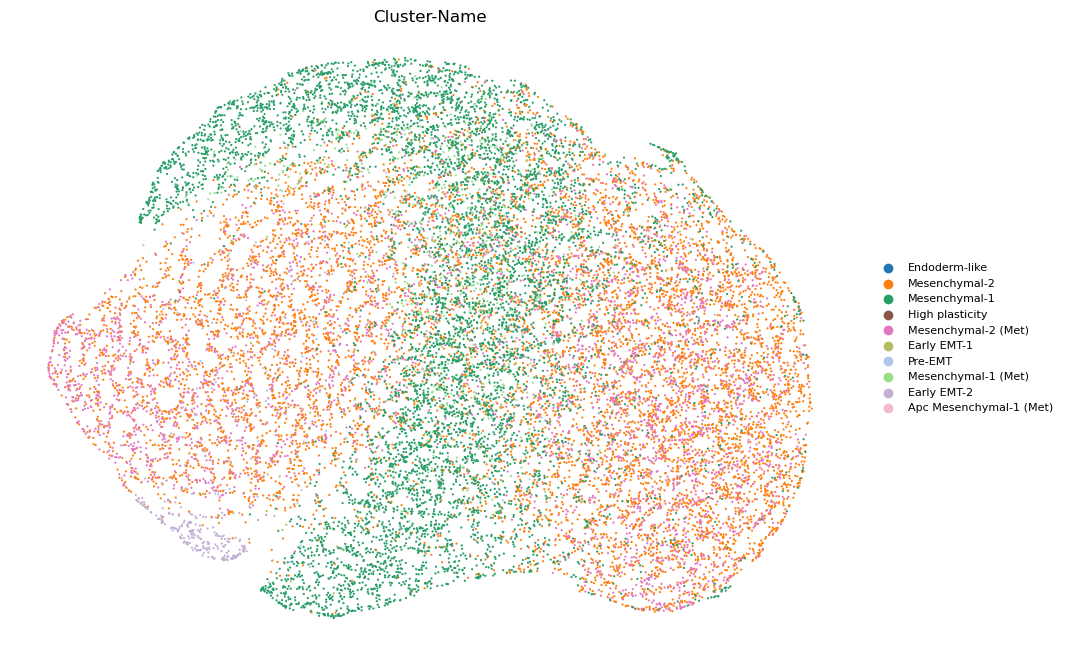

In [19]:
adata.obs['subtree_full'] = adata.obs['subtree'].copy()
adata.obs['subtree'] = adata.obs['subtree'].astype('category')
N = 10
top_cats = adata.obs['subtree'].value_counts().nlargest(N).index

adata.obs['subtree'] = (
    adata.obs['subtree']
    .astype('object')
    .where(adata.obs['subtree'].isin(top_cats), 'others')
    .astype('category')
)

plot_umap_embeddings(adata, rep_keys=["DeepTracing_UV"],
                     color_keys=["Tumor", "subtree", "Cluster-Name"], size=10, name=name, results_path=results_path)
plot_umap_embeddings(adata, rep_keys=["DeepTracing_IV"],
                     color_keys=["Tumor", "Cluster-Name"], size=10, name=name, results_path=results_path)

Evaluating Tumor Type Conservation...


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 5/5 [00:32<00:00,  6.44s/it]o conservation: silhouette_label]

                                                                                          

Evaluating Lineage Conservation...


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 5/5 [01:09<00:00, 13.89s/it]o conservation: silhouette_label]

                                                                                          

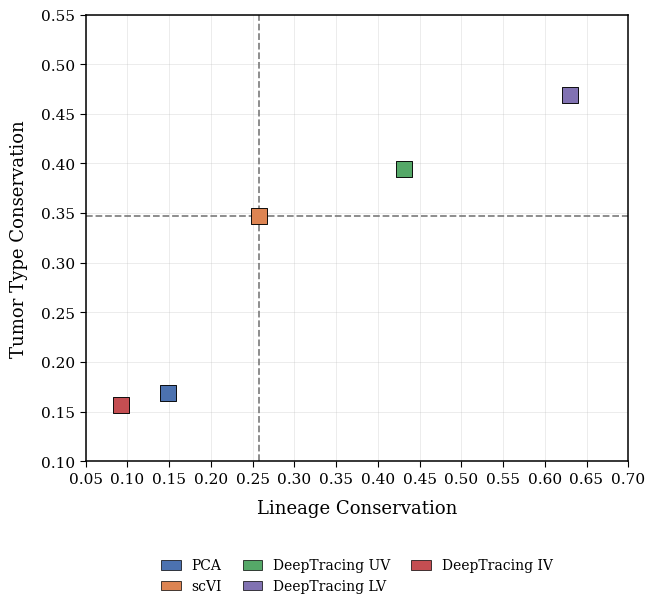

In [20]:
embedding_keys = ["PCA", "scVI", "DeepTracing_UV", "DeepTracing_LV", "DeepTracing_IV"]
label_configs = [("Tumor Type", "Tumor"), ("Lineage", "subtree_full")]

full_metrics, summary_scores, benchmarkers, scatter_files = evaluate_scib(
    adata=adata,
    embedding_keys=embedding_keys,
    label_configs=label_configs,
    output_dir=f"./evaluation_metrics_results_{name}",
    n_jobs=8,
    show=True,
    scatter_pairs=[("Lineage Conservation", "Tumor Type Conservation")],
)
